In [1]:
import pandas as pd
import numpy as np
import regex as re
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r'D:\Download\doc\SK_WIDIASIH\dataset_kompas\databersih\data_jeniskriminal_SMOTE.csv')

In [4]:
df.head()

,judul_berita,isi_berita,text_clean,label_kriminal,label_krim_gabungan,jenis_kriminal,prediksi_jenis_dt
0,Bocah yang Jasadnya Terbungkus Sarung Tewas Di...,"JAKARTA, KOMPAS.com - Pasangan pengemis bernam...",pasangan pengemis bernama sinta dewi 22 aidil ...,True,1,Pembunuhan,Pembunuhan
1,Orangtua Bocah Tewas dalam Sarung Sering Aniay...,"JAKARTA, KOMPAS.com - Sinta Dewi (22) dan Aidi...",sinta dewi 22 aidil zacky rahman 19 pengemis d...,True,1,Penganiayaan & Kekerasan,Penganiayaan & Kekerasan
2,Orangtua Bocah Tewas dalam Sarung Aniaya Anakn...,"JAKARTA, KOMPAS.com - Dua pengemis bernama Sin...",pengemis bernama sinta dewi 22 aidil zacky rah...,True,1,Pembunuhan,Penganiayaan & Kekerasan
3,Orangtua Bocah Tewas Terbungkus Sarung di Beka...,"JAKARTA, KOMPAS.com - Balita berinisial RMR (3...",balita berinisial rmr 3 ditemukan tewas terbun...,True,1,Penganiayaan & Kekerasan,Penganiayaan & Kekerasan
4,"Motif Orangtua Bunuh Anak di Bekasi, Emosi kar...","JAKARTA, KOMPAS.com - Polisi mengungkapkan, or...",polisi orangtua bernama sinta dewi 22 aidil za...,True,1,Pembunuhan,Pembunuhan


In [5]:
print("Jumlah baris data:")
jumlah_baris = len(df)
print(f"   Total baris data: {jumlah_baris}")

Jumlah baris data:
   Total baris data: 75030


In [6]:
jumlah_duplikasi = df.duplicated().sum()
print("Cek data duplikasi:")
print(f"   Jumlah baris duplikat: {jumlah_duplikasi}")

Cek data duplikasi:
   Jumlah baris duplikat: 0


In [7]:
print("Cek data kosong (Missing Values):")
data_kosong = df.isnull().sum()
print(data_kosong)

Cek data kosong (Missing Values):
judul_berita           0
isi_berita             0
text_clean             0
label_kriminal         0
label_krim_gabungan    0
jenis_kriminal         0
prediksi_jenis_dt      0
dtype: int64


In [8]:
def compile_keywords_motif(word_list):
    return re.compile(rf"\b({'|'.join(map(re.escape, list(set(word_list))))})\b", re.IGNORECASE)

list_narkoba_alkohol = [
    'alat hisap', 'alkohol', 'alprazolam', 'apotek rakyat', 'arak', 'benzo', 'bong', 'botol miras', 
    'ciu', 'di bawah pengaruh alkohol', 'diazepam', 'dumolid', 'ekstasi', 'eximer', 'ganja', 
    'ganja cair', 'heroin', 'hexymer', 'home industri sabu', 'ineks', 
    'kokain', 'kondisi mabuk', 'kratom', 'kurir narkoba', 'ladang ganja', 'liquid ganja',
    'mabuk berat', 'mabuk-mabukan', 'mdma', 'mengisap sabu', 'methamphetamine', 'minuman keras', 
    'miras', 'miras oplosan', 'narkoba', 'narkoba cair', 'narkoba jenis baru', 'narkotika', 
    'nyabu', 'obat daftar g', 'oplosan', 'pabrik sabu', 'pasal narkotika', 'pecandu', 
    'pecandu narkotika', 'pemuda mabuk', 'pengaruh alkohol', 'pengguna narkoba', 
    'pengungkapan kasus narkoba', 'penyalahguna narkoba', 'penyalahgunaan narkoba', 
    'pesta ganja', 'pesta miras', 'pesta narkoba', 'pesta narkotika', 'pesta sabu', 'pil koplo', 
    'positif narkoba', 'psikotropika', 'psikotropika gol 1', 'putauw', 'riklona', 'sabu', 
    'sabu antar provinsi', 'sabu dalam kemasan teh', 'sabu kristal', 'sabu sabu', 
    'satresnarkoba', 'shabu-shabu', 'sinte', 'tangkap tangan narkoba', 'teler', 'tembakau gorila', 
    'tembakau sintetis', 'terpengaruh miras', 'tramadol', 'transaksi narkotika', 'trihexyphenidyl', 
    'tuak', 'undang-undang narkotika', 'uu narkotika'
]

list_seksual = [
    'aksi bejat', 'ancam bunuh diri', 'ancam keluarga', 'ancam sakiti anak', 'ancaman akan disebar', 'bercerai dengan suami','perempuan dinikahi','perselingkuhan', 'cemburu', 'mantan suami', 'bercerai dengan suami', 'perempuan dinikahi', 'perebutan pasangan', 'cinta segitiga',
    'ancaman penyebaran foto', 'ancaman sebar aib', 'ancaman sebar foto', 'ancaman sebar video', 
    'apartemen bo', 'asmara', 'begal bokong', 'begal payudara', 'berkas asusila', 'bermotif asmara', 
    'berselingkuh', 'bersetubuh', 'budak seks', 'bugil', 'cabul', 'catcalling', 'cemburu', 
    'cemburu buta', 'child groming', 'child sexual abuse material', 'cinta segitiga', 'ciuman paksa', 
    'colek bagian vital', 'csam', 'deepfake asusila', 'deepfake porno', 'di luar nikah', 'dicabuli', 
    'diduga diperkosa', 'diduga selingkuhannya', 'digagahi', 'dijual', 'dikejar mantan', 'dilecehkan', 
    'dipaksa melayani', 'diperkosa', 'dirudapaksa', 'disetubuhi', 'disodomi', 'ditolak bersetubuh', 
    'ditolak cintanya', 'dugaan asusila', 'ekshibisionis', 'eksploitasi seksual', 
    'eksploitasi seksual anak', 'fetish', 'foto tanpa busana', 'gagal move on', 'gagahi', 'gang rape', 
    'germo', 'gesek', 'grepe', 'grup telegram mesum', 'guncang prostitusi', 'hasil visum asusila', 
    'hubungan asmara korban', 'hubungan gelap', 'hubungan sedarah', 'inses', 'jual diri', 
    'kamera tersembunyi toilet', 'kasus asusila', 'kehamilan di luar nikah dipaksa', 'kebiadaban seksual', 
    'kekerasan seksual', 'kekerasan seksual anak', 'kekerasan seksual berbasis elektronik', 
    'kerusakan alat vital', 'korban kebiadaban', 'korban pelecehan', 'ksbe', 'lantaran berbeda keyakinan', 
    'laporan asusila', 'link video syur', 'melalui media elektronik', 'melangsungkan kawin siri', 
    'melecehkan', 'membakar api cemburu', 'mencabuli', 'mengandung anak tersangka', 'mengaku kehamilan', 
    'menggagahi', 'menjalani hubungan pernikahan', 'menolak bersetubuh', 'menolak melayani nafsu', 
    'menyetubuhi', 'mesum', 'mucikari', 'mucikari online', 'muncikari', 'nafsu setan', 'obsesi asmara', 
    'oknum asusila', 'oknum guru cabul', 'open bo', 'orang ketiga', 'pacar', 'paksa buka baju', 
    'paksa buka pakaian', 'panti pijat mesum', 'pap bugil', 'patah hati', 'pedofil', 'pedofilia', 
    'pelecehan', 'pelecehan di angkutan', 'pelecehan fisik', 'pelecehan non fisik', 'pelecehan seksual', 
    'pelecehan seksual fisik', 'pelukan paksa', 'pemaksaan hubungan', 'pemaksaan seksual', 
    'pemeraman seksual', 'pemerasaan seksual', 'pemuas birahi', 'pemuas hidung belang', 'pemuas nafsu', 
    'pembunuhan berencana mantan', 'pemerkosaan', 'pemerkosaan anak', 'pemerkosaan bergilir', 
    'pencabulan', 'pencabulan anak di bawah umur', 'pencabulan santri', 'pengaduan asusila', 
    'penggerangan', 'penguntitan', 'penguntitan mantan', 'penolakan cinta', 'penyebaran foto syur', 
    'penyebaran konten asusila', 'penyebaran video intim', 'perbuatan bejat', 'perbuatan cabul', 
    'perdagangan anak prostitusi', 'perempuan pelakor', 'perkosa', 'perselingkuhan', 'persetubuhan', 
    'persetubuhan anak', 'perzinaan', 'pesta gay', 'pesta lesbian', 'pesta seks', 'pijat plus plus', 
    'pil', 'pornografi', 'posesif', 'predator anak', 'pria hidung belang', 'pria idaman', 
    'pria idaman lain', 'prostitusi', 'prostitusi online', 'prostitusi terselubung', 'remas', 
    'revenge porn', 'rudapaksa', 'sakit hati asmara', 'sakit hati diputus', 'seks komersial', 
    'seks komersial anak', 'selingkuh', 'selingkuhannya', 'setubuhi', 'sextortion', 'skandal seks', 
    'sodomi', 'spycam', 'stalking asmara', 'stalking seksual', 'syur', 'terbakar api cemburu', 
    'terbakar cemburu', 'teror asmara', 'teror konten intim', 'teror mantan', 'tidak direstui', 
    'tindakan asusila', 'tindakan tidak senonoh', 'tpks', 'uu tpks', 'vcs', 'video bokep', 
    'video mesum', 'video syur', 'visum kemaluan', 'visum korban kekerasan seksual', 'wanita idaman', 
    'wanita idaman lain', 'wil', 'kekasih', 'mantan kekasih', 'mantan suami istri', 'mantan tunangan'
]

list_ekonomi = [
    'aksi copet', 'aksi todong', 'akuisisi paksa', 'aliran dana', 'aliran dana haram', 'anggaran fiktif', 
    'apk palsu', 'aplikasi bodong', 'arisan bodong', 'aset bandar', 'bancakan anggaran', 'bandar besar', 
    'bandar judi', 'bea cukai', 'begal', 'begal motor', 'bekas pengantin pesanan', 'bisnis haram', 
    'bisnis hitam', 'bunga fiktif', 'bunga pinjol', 'carding', 'cek kosong', 'copet', 'copet dompet', 
    'copet hp', 'crypto fraud', 'cuci uang', 'curanmor', 'curas', 'curat', 'curi', 'curi motor', 'keuntungan ekonomi',
    'dana siluman', 'dana talangan', 'deposito bodong', 'dibegal', 'dicuri', 'dijambret', 'dipalak', 
    'diperjualbelikan ilegal', 'dirampok', 'diselundupkan', 'diteror penagih', 'dugaan penipuan karyawan', 
    'dukun pengganda', 'eksekusi jaminan', 'faktur pajak fiktif', 'fee', 'fee proyek', 'fraud', 'penambang emas ilegal','penambang ilegal',
    'gadai fiktif', 'galian c ilegal', 'gandakan uang', 'gasak', 'gembok paksa', 'gondol', 'gratifikasi', 
    'gurita bisnis narkoba', 'gusur', 'hadiah palsu', 'harta gono gini', 'hasil curian', 'hutang', 
    'hutang piutang', 'ilegal akses', 'illegal mining', 'impor ilegal', 'investasi', 'investasi bodong', 
    'investasi crypto', 'investasi ilegal', 'jambret', 'jambret hp', 'jambret ponsel', 'jambret tas', 
    'jambretan', 'jarah', 'jatah preman', 'jebol rekening', 'jual beli nomor rekening', 'jual beli rekening', 
    'judi online', 'judol', 'kebocoran anggaran', 'keuntungan berlipat', 'keuntungan penjualan', 
    'klaim tanah', 'klik link palsu', 'kode otp', 'kompromi ekonomi', 'korban penipuan', 'korupsi', 
    'korupsi berjamaah', 'korupsi dana', 'kurir paket palsu', 'kuras mbanking', 'kuras rekening', 
    'kuras saldo', 'ladang bisnis ilegal', 'layanan pelanggan palsu', 'leasing', 'link palsu', 
    'link phising', 'loker palsu', 'love scamming', 'm banking dibobol', 'mafia anggaran', 'mafia ppatk', 
    'mafia proyek', 'mafia tanah', 'malak', 'maling', 'maling hp', 'maling motor', 'manipulasi anggaran', 
    'manipulasi laporan keuangan', 'mark up', 'memalaknya', 'membobol brankas', 'membobol rekening', 
    'membobol rekening nasabah', 'memperkaya diri sendiri', 'mempromosikan situs judi', 'mencopet ponsel', 
    'mencuri', 'menagih janji fee', 'menagih uang', 'mengedarkan', 'menggasak', 'menggelapkan', 
    'menggelapkan aset', 'menggelapkan mobil', 'menggelapkan uang', 'mengoplos', 'menguasai aset', 
    'menguasai aset suaminya', 'menguasai harta', 'menguasai lahan', 'menipunya', 'menjambret', 
    'menyunat dana bantuan', 'merampas harta', 'meraup keuntungan fantastis', 'money laundering', 
    'monopoli pasar gelap', 'nilep uang', 'omzet', 'pakaian bekas impor', 'palsu mbanking', 'gara gara uang','motifnya butuh uang','motif keuangan',
    'pekerja fiktif', 'pembagian harta', 'pembagian waris', 'pembagian warisan', 'pembajak menyandera kapal', 
    'pembongkaran ruko', 'pemalakan', 'pemalsuan', 'pembebasan lahan', 'pembegalan', 'pemerasan', 
    'pemerasan pinjol', 'penadah', 'penadahan', 'penadahan barang', 'penadahan mobil', 'penadahan motor', 
    'penagih hutang', 'penagih utang', 'penambangan ilegal', 'pencatutan nama', 'pencopetan', 
    'pencucian uang', 'pencucian uang korupsi', 'pencucian uang sindikat', 'pencuri', 'pencurian', 
    'pencurian data', 'pencurian hewan', 'pencurian kripto', 'pencurian ternak', 'pendanaan gelap jaringan', 
    'pendudukan lahan', 'pengantin pesanan', 'pengedar narkoba', 'pengedaran senjata api', 'penggelapan', 
    'penggelapan aset', 'penggelapan jabatan', 'penggelapan pajak', 'penggusuran paksa', 'pengosongan lahan', 
    'pengosongan rumah sepihak', 'penguasaan lahan', 'penipuan', 'penipuan lowongan kerja', 'penipuan online', 
    'penilapan', 'penilapan uang', 'penjambret', 'penjambretan', 'penjambretan iphone', 'penimbunan kekayaan ilegal', 
    'penyelewengan', 'penyelewengan dana', 'penyelewengan pengangkutan niaga', 'penyelewengan penilapan uang', 
    'penyerobotan lahan', 'penyerobotan tanah', 'penyitaan ilegal', 'penyelundupan', 'perampasan', 
    'perampasan aset', 'perampasan hp', 'perampasan mobil', 'perampasan motor', 'perampok', 'perampokan', 
    'perampokan di kantor', 'perdagangan orang', 'peredaran uang rahasia', 'perebutan harta', 'markas judi online',
    'perebutan waris', 'perebutan warisan', 'permainan anggaran', 'perompak tebusan', 'perputaran uang', 
    'perputaran uang hitam', 'persaingan bisnis', 'phising link', 'phishing', 'pig butchering scam', 
    'pinjol', 'pinjol ilegal', 'proyek fiktif', 'pundi pundi haram', 'pungli', 'pungutan', 'pungutan liar', 
    'raib', 'rampas', 'rampas hp', 'rampas motor', 'rampok', 'ransom', 'ransomware', 'rebutan waris', 
    'rekening gendut', 'rekening penampung', 'saldo habis', 'saldo ludes', 'scammer', 'scamming', 
    'selundup baju bekas', 'sengketa bangunan', 'sengketa lahan', 'sengketa tanah', 'sengketa warisan', 
    'sertifikat ganda', 'sertifikat palsu', 'setoran tunai fiktif', 'sindikat uang palsu', 'skema ponzi', 
    'skimming', 'soceng', 'sogokan', 'suap', 'suap pengondisian kasus', 'suap proyek', 'sunat dana', 
    'supplier fiktif', 'takeover rekening', 'tebusan', 'teror pinjol', 'thrifting ilegal', 'tipu', 
    'token listrik palsu', 'top up fiktif', 'tppo', 'trafficking', 'transaksi mencurigakan', 
    'transaksi narkoba', 'transaksi pasar gelap', 'transaksi penjualan senjata', 'transfer fiktif', 
    'uang palsu', 'uang pelicin', 'uang rakyat menguap', 'undian gratis', 'upal', 'utang piutang', 'warisan'
]

list_dendam = [
    'adu fisik', 'adu mulut', 'aksi spontan', 'aksi sweeping', 'amuk massa', 'ancaman', 'anarki', 
    'balas', 'balas dendam', 'banting', 'baper', 'batas lahan', 'batas tanah', 'benci mendalam', 
    'bentrok ormas', 'bentrokan antarkelompok', 'bentrokan fisik', 'bentrokan warga', 'berantem', 
    'berkelahi', 'caci maki', 'carok', 'cekcok', 'cekcok mulut', 'cekcok tetangga', 'dendam', 
    'dendam kesumat', 'dendam lama', 'dibanting', 'dicaci maki', 'diejek', 'diejek di media sosial', 
    'dihakimi massa', 'dihina', 'dipermalukan', 'ditegur', 'duel', 'ejek', 'eksekusi massa', 
    'emosi', 'emosi kekhilafan massa', 'emosi meledak', 'emosi tersangka', 'fitnah', 'gaduh', 
    'gelap mata', 'harga diri', 'harga diri terusik', 'hilang akal', 'hilang akal sehat', 
    'hilang kesabaran', 'hina', 'intimidasi', 'iri dengki', 'iseng', 'jatuh harga diri', 'jengkel', 
    'kalap', 'kebencian', 'kebencian dalam diri', 'kekesalan', 'kekesalan santri', 'kekhilafan', 
    'kerusuhan', 'kesal', 'kesalahpahaman', 'ketegangan antarwarga', 'ketegangan memuncak', 
    'klitih', 'konflik horisontal', 'konflik keluarga', 'korban iseng mengotori', 'korban mengejeknya', 
    'lepas kendali', 'lepas kontrol', 'main hakim sendiri', 'malu', 'marah', 'marah besar', 
    'masalah sepele', 'membanting', 'memaki', 'memarahi', 'memprovokasi', 'menantang duel', 
    'menduga uang dicuri', 'menegur', 'mengejeknya', 'menaruh dendam', 'menyimpan dendam', 
    'merasa dipermalukan', 'murka', 'musik keras', 'naik darah', 'naik pitam', 'pencemaran nama baik', 
    'pengeroyokan', 'pengeroyokan brutal', 'pengeroyokan massa', 'penyerangan berkelompok sabana', 
    'perang kampung', 'perang suku', 'perbuatan bejat', 'perebutan wilayah', 'perkara batas', 
    'perkelahian', 'perkelahian satu lawan satu', 'persekusi', 'perselisihan', 'perselisihan berkelanjutan', 
    'perselisihan warga', 'pertengkaran', 'provokasi', 'rasial', 'rebutan', 'rebutan lahan', 'ribut', 
    'ribut tetangga', 'sakit hati', 'sakit hati diejek', 'sakit hati dihina', 'sakit hati dimarahi', 
    'sakit hati dipecat', 'sakit hati ditegur', 'sakit hati karena perkataan', 'sakit hati mendalam', 
    'salah paham', 'salah paham di jalan', 'salah paham tetangga', 'saling ejek medsos', 'saling tantang', 
    'santet', 'sara', 'senggolan kendaraan', 'sengketa', 'sengketa tanah', 'sentimen', 'simpan dendam', 
    'suara berisik', 'suara knalpot bising', 'sweeping ormas', 'tantang duel', 'tantangan duel', 
    'tawuran', 'tikai', 'tidak terima', 'tidak terima ditegur', 'tidak terima diputus', 'tersinggung', 
    'tersinggung ucapan', 'tersulut', 'tersulut emosi', 'ujaran kebencian'
]

pat_narkoba_alkohol = compile_keywords_motif(list_narkoba_alkohol)
pat_seksual = compile_keywords_motif(list_seksual)
pat_ekonomi = compile_keywords_motif(list_ekonomi)
pat_dendam = compile_keywords_motif(list_dendam)

def label_motif(row):
    text = f" {str(row['text_clean'])} ".lower()
    
    hits_narkoba_alkohol = set(pat_narkoba_alkohol.findall(text))
    hits_seksual = set(pat_seksual.findall(text))
    hits_ekonomi = set(pat_ekonomi.findall(text))
    hits_dendam = set(pat_dendam.findall(text))

    scores = {
        'Narkotika & Alkohol': len(hits_narkoba_alkohol) * 20,
        'Asmara & Kejahatan Seksual': len(hits_seksual) * 20,
        'Ekonomi & Harta Benda': len(hits_ekonomi) * 20,
        'Dendam, Emosi & Konflik': len(hits_dendam) * 20
    }

    pattern_asmara = r'\b(pelecehan\s+seksual|diperkosa|asusila|pencabulan|cemburu|perselingkuhan|selingkuhan|siri|sirinya)\b|\bmantan\s+(pacar|kekasih|suami|istri|pasangan|tunangan)\b'
    if re.search(pattern_asmara, text):
        scores['Asmara & Kejahatan Seksual'] += 70

    if re.search(r'\b(mengisap\s+sabu|memakai\s+ganja|paranoid|halusinasi|pengaruh\s+alkohol|pengaruh\s+miras|dalam\s+kondisi\s+mabuk|penyalahgunaan\s+narkoba|penyalahgunaan\s+ganja|penyalahgunaan\s+narkoba|penyalahgunaan\s+sabu)\b', text):
        scores['Narkotika & Alkohol'] += 300

    if re.search(r'\b(pembunuh\s+bayaran|otak\s+pembunuhan|menyuruh\s+pembunuhan|menyuruh\s+membunuh|eksekutor)\b', text):
        if re.search(r'\b(dendam|sakit\s+hati|mantan|istri|suami|bercerai|cerai|anak)\b', text):
            scores['Dendam, Emosi & Konflik'] += 150

    if re.search(r'\b(mengambil\s+uang|menikmati\s+uang|uang\s+hasil\s+kejahatan)\b', text):
        if not re.search(r'\b(pembunuh\s+bayaran|mantan\s+istri|mantan\s+suami)\b', text):
            scores['Ekonomi & Harta Benda'] += 80

    if scores['Narkotika & Alkohol'] > 0:
        if not re.search(r'\b(pengedar\s+narkoba|penyelundupan|mengedarkan\s+narkoba|pengedar\s+sabu|pengedar\s+ganja|menggagalkan\s+pengiriman\s+narkotika)\b', text):
            scores['Ekonomi & Harta Benda'] = 0
        else:
            scores['Ekonomi & Harta Benda'] += 100

    if re.search(r'\b(menganiaya|penganiayaan|brutal|menendang|memukul|menginjak|mutilasi|percekcokan)\b', text):
        if re.search(r'\b(emosi|marah|kesal|dendam|sakit\s+hati)\b', text):
            scores['Dendam, Emosi & Konflik'] += 50

    if re.search(r'\b(konflik\s+agraria|sengketa\s+lahan|mengambil\s+uang|menikmati\s+uang|uang\s+hasil\s+kejahatan|perdagangan\s+orang|tppo|penggelapan\s+mobil|penipuan|order\s+fiktif|penggelapan|korupsi|hutang|penagihan\s+utang|utang|warisan|menguasai\s+harta|pencucian\s+uang|penguasaan\s+aset|menguasai\s+aset\s+suaminya|menguasai\s+aset|menguasai\s+harta)\b', text):
        scores['Ekonomi & Harta Benda'] += 300

    if re.search(r'\b(kdrt|kekerasan\s+dalam\s+rumah\s+tangga|femisida)\b', text):
        scores['Dendam, Emosi & Konflik'] += 100
        if not re.search(r'\b(rampok|curi|maling|jambret|gasak)\b', text):
            scores['Ekonomi & Harta Benda'] = 0

    if re.search(r'\b(begal\s+payudara|begal\s+bokong)\b', text):
        scores['Asmara & Kejahatan Seksual'] += 100
        if not re.search(r'\b(ambil|rampas|curi|hilang|gasak|raib|hp|ponsel|uang|dompet)\b', text):
            scores['Ekonomi & Harta Benda'] = 0

    if re.search(r'\b(kpk|komisi\s+pemberantasan\s+korupsi|pemberantasan\s+korupsi|korupsi)\b', text) and \
       re.search(r'\b(penyiraman\s+air\s+keras|air\s+keras|kdrt|memperkosa)\b', text):
        scores['Ekonomi & Harta Benda'] = 0

    is_tuduh = re.search(r'\b(tuduh|dituduh|menuduh|teriak|diteriaki|tepergok|kepergok|memergoki|dikeroyok\s+warga|dikeroyok|narkotika|peredaran\s+narkotika|tewasnya)\b', text)
    is_maling = re.search(r'\b(maling|pencuri|curi|rampok|begal|jambret|narkotika|pencurian)\b', text)
    is_kekerasan = re.search(r'\b(diamuk\s+massa|menggeruduk\s+membakar\s+rumah|dihajar|dimassa|dipukuli|pengeroyokan|tewas|dianiaya|amuk\s+massa|massa|emosi|kekhilafan\s+massa|tidak\s+membayar\s+tarif|warga\s+melampiaskan\s+kemarahan|aksi\s+massa)\b', text)
    
    if is_tuduh and is_maling and is_kekerasan:
        scores['Ekonomi & Harta Benda'] = 0
        scores['Dendam, Emosi & Konflik'] += 150

    max_score = max(scores.values())
    if max_score < 20:
        return 'Tidak Teridentifikasi'

    top_labels = [label for label, score in scores.items() if score == max_score]
    if len(top_labels) > 1:
        prioritas = ['Narkotika & Alkohol','Ekonomi & Harta Benda','Asmara & Kejahatan Seksual', 'Dendam, Emosi & Konflik']
        for p in prioritas:
            if p in top_labels:
                return p
    return top_labels[0]

tqdm.pandas()
df['motif_kejahatan'] = df.progress_apply(label_motif, axis=1)

100%|██████████| 75030/75030 [08:16<00:00, 151.04it/s]


In [9]:
dist_kriminal = pd.DataFrame({
    'Jumlah': df['motif_kejahatan'].value_counts(dropna=False),
    'Persentase (%)': (df['motif_kejahatan'].value_counts(dropna=False, normalize=True) * 100).round(2)
})

print("=== DISTRIBUSI MOTIF ===")
print(dist_kriminal)

=== DISTRIBUSI MOTIF ===
                            Jumlah  Persentase (%)
motif_kejahatan                                   
Ekonomi & Harta Benda        30426           40.55
Dendam, Emosi & Konflik      14293           19.05
Asmara & Kejahatan Seksual   12266           16.35
Tidak Teridentifikasi        11174           14.89
Narkotika & Alkohol           6871            9.16


## CEK

In [ ]:
pd.set_option('display.max_colwidth', None)
df_sampel = df[df['label_kriminal'] == True].sample(n=10)

for index, row in df_sampel.iterrows():
    print(f"LABEL Jenis: {row['motif_kejahatan']} | INDEX: {index}")
    print(f"BERITA ISI : {row['text_clean']}")
    print("-" * 80)
    print("\n")

In [ ]:
pd.set_option('display.max_colwidth', None)
df_sampel = df[(df['label_kriminal'] == True) & (df['motif_kejahatan'] == 'Tidak Teridentifikasi')].sample(n=10)

for index, row in df_sampel.iterrows():
    print(f"LABEL Jenis: {row['motif_kejahatan']} | INDEX: {index}")
    print(f"BERITA ISI : {row['text_clean']}")
    print("-" * 80)
    print("\n")

In [ ]:
target_indices = [8344,12253,66230,22271,33052,53987,21135,40160]

for idx in target_indices:
    if idx in df.index:
        print(f"INDEX           : {idx}")
        print(f"LABEL MOTIF     : {df.loc[idx, 'motif_kejahatan']}")
        print(f"BERITA ISI      : \n{df.loc[idx, 'text_clean']}")
        print("\n" + "="*80 + "\n")
    else:
        print(f"Index {idx} tidak ditemukan dalam DataFrame.")

## ML

In [10]:
df_clean_kelas = df[df['motif_kejahatan'] != 'Tidak Teridentifikasi']

X_train, X_test, y_train, y_test = train_test_split(
    df_clean_kelas['text_clean'],
    df_clean_kelas['motif_kejahatan'],
    test_size=0.2,
    random_state=42,
    stratify=df_clean_kelas['motif_kejahatan']
)

In [11]:
URUTAN_KELAS = sorted(y_train.unique())

tfidf = TfidfVectorizer(ngram_range=(1, 3), max_features=25000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [12]:
model_gini = DecisionTreeClassifier(criterion='gini', random_state=42)
model_gini.fit(X_train_tfidf, y_train)

pred_test_gini = model_gini.predict(X_test_tfidf)

                            precision    recall  f1-score   support

Asmara & Kejahatan Seksual       0.90      0.88      0.89      2453
   Dendam, Emosi & Konflik       0.83      0.84      0.83      2859
     Ekonomi & Harta Benda       0.93      0.94      0.93      6086
       Narkotika & Alkohol       0.89      0.89      0.89      1374

                  accuracy                           0.90     12772
                 macro avg       0.89      0.89      0.89     12772
              weighted avg       0.90      0.90      0.90     12772



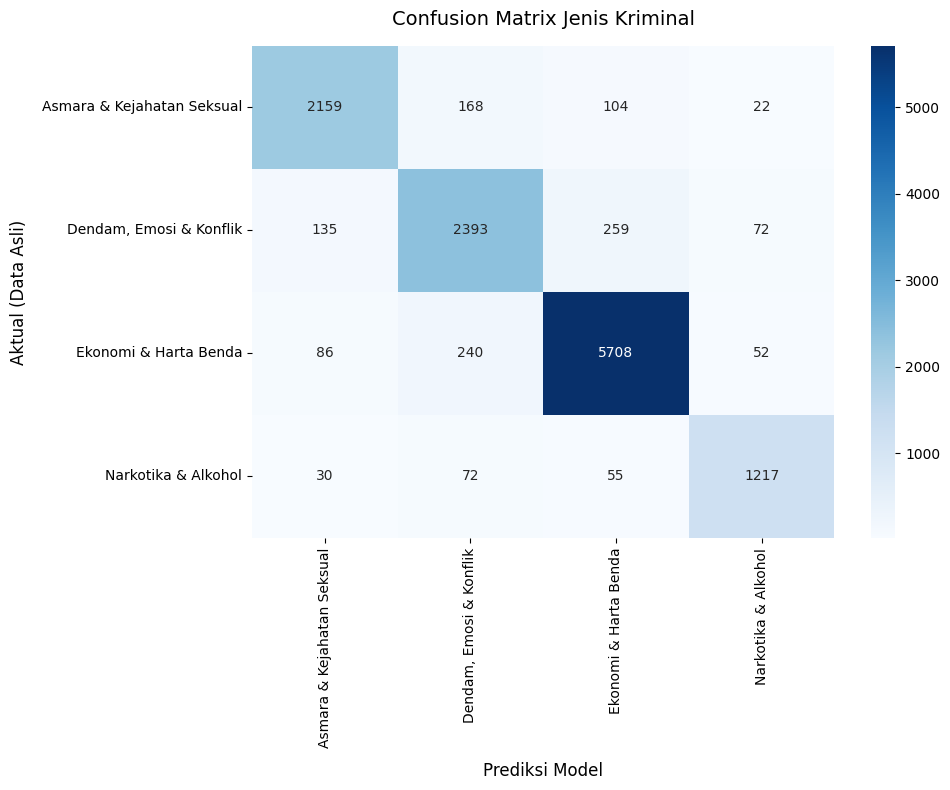


ANGKA CONFUSION MATRIX:

Data Asli [Asmara & Kejahatan Seksual] didistribusikan ke prediksi:
  -> Ditebak Asmara & Kejahatan Seksual: 2159
  -> Ditebak Dendam, Emosi & Konflik: 168
  -> Ditebak Ekonomi & Harta Benda: 104
  -> Ditebak Narkotika & Alkohol: 22

Data Asli [Dendam, Emosi & Konflik] didistribusikan ke prediksi:
  -> Ditebak Asmara & Kejahatan Seksual: 135
  -> Ditebak Dendam, Emosi & Konflik: 2393
  -> Ditebak Ekonomi & Harta Benda: 259
  -> Ditebak Narkotika & Alkohol: 72

Data Asli [Ekonomi & Harta Benda] didistribusikan ke prediksi:
  -> Ditebak Asmara & Kejahatan Seksual: 86
  -> Ditebak Dendam, Emosi & Konflik: 240
  -> Ditebak Ekonomi & Harta Benda: 5708
  -> Ditebak Narkotika & Alkohol: 52

Data Asli [Narkotika & Alkohol] didistribusikan ke prediksi:
  -> Ditebak Asmara & Kejahatan Seksual: 30
  -> Ditebak Dendam, Emosi & Konflik: 72
  -> Ditebak Ekonomi & Harta Benda: 55
  -> Ditebak Narkotika & Alkohol: 1217


In [15]:
print(classification_report(y_test, pred_test_gini, target_names=URUTAN_KELAS))

cm = confusion_matrix(y_test, pred_test_gini, labels=URUTAN_KELAS)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=URUTAN_KELAS,
    yticklabels=URUTAN_KELAS
)
plt.title('Confusion Matrix Motif Kejahatan', fontsize=14, pad=15)
plt.xlabel('Prediksi Model', fontsize=12, labelpad=10)
plt.ylabel('Aktual (Data Asli)', fontsize=12, labelpad=10)
plt.tight_layout()
plt.show()

print("\nANGKA CONFUSION MATRIX:")
for i, kelas_asli in enumerate(URUTAN_KELAS):
    print(f"\nData Asli [{kelas_asli}] didistribusikan ke prediksi:")
    for j, kelas_pred in enumerate(URUTAN_KELAS):
        if cm[i][j] > 0: 
            print(f"  -> Ditebak {kelas_pred}: {cm[i][j]}")

In [16]:
df_hasil_bersih = df_clean_kelas.copy()

X_clean_tfidf = tfidf.transform(df_hasil_bersih['text_clean'])

prediksi_bersih = model_gini.predict(X_clean_tfidf)

df_hasil_bersih['prediksi_motif_dt'] = prediksi_bersih

nama_file_final = "data_motifkejahatan.csv"
df_hasil_bersih.to_csv(nama_file_final, index=False)